# EKF Analysis: Quaternion 16-state EKF

Analysis of the new quaternion drone-physics EKF across four scenarios:
**rest**, **constant velocity**, **acceleration**, **constant turn**.

Data is recorded with `scenario_record.launch.py` using `test_ekf.yaml`.
Each test directory contains:
- `scenario_data.csv` — EKF odometry (pose + twist + covariance)
- `accel_data.csv`    — EKF accel output (linear + angular accel + covariance)

In [111]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
import yaml

## Utility functions

In [112]:
# Always use scientific notation on all axes
plt.rcParams.update({
    "axes.formatter.use_mathtext": True,
    "axes.formatter.limits": (0, 0),
})


def add_rpy_from_quat(
    input_df: pd.DataFrame,
    xq_col: str = "xq",
    yq_col: str = "yq",
    zq_col: str = "zq",
    w_col: str = "w",
) -> pd.DataFrame:
    """Add roll, pitch, yaw (degrees) columns derived from quaternion columns.

    Uses the standard ZYX (yaw-pitch-roll) Euler decomposition.

    Args:
        input_df: DataFrame with quaternion columns.
        xq_col, yq_col, zq_col, w_col: Column names for the quaternion components.

    Returns:
        Copy of input_df with added columns 'roll_deg', 'pitch_deg', 'yaw_deg'.
    """
    df = input_df.copy()
    x = df[xq_col].to_numpy()
    y = df[yq_col].to_numpy()
    z = df[zq_col].to_numpy()
    w = df[w_col].to_numpy()

    # Roll
    t0 = 2.0 * (w * x + y * z)
    t1 = 1.0 - 2.0 * (x * x + y * y)
    roll = np.arctan2(t0, t1)

    # Pitch
    t2 = np.clip(2.0 * (w * y - z * x), -1.0, 1.0)
    pitch = np.arcsin(t2)

    # Yaw
    t3 = 2.0 * (w * z + x * y)
    t4 = 1.0 - 2.0 * (y * y + z * z)
    yaw = np.arctan2(t3, t4)

    df["roll_deg"]  = np.rad2deg(roll)
    df["pitch_deg"] = np.rad2deg(pitch)
    df["yaw_deg"]   = np.rad2deg(yaw)
    return df


def find_t_rel(df: pd.DataFrame) -> pd.Series:
    """Return relative time (seconds) starting from zero."""
    t_abs = df["t_sec"] + df["t_nsec"] * 1e-9
    return t_abs - t_abs.iloc[0]


def trim_to_duration(df: pd.DataFrame, max_sec: float) -> pd.DataFrame:
    """Drop rows beyond max_sec from the start of the recording."""
    return df[find_t_rel(df) <= max_sec].reset_index(drop=True)


def subtract_velocity_trend(df: pd.DataFrame, velocity: float) -> pd.DataFrame:
    """Remove a constant-velocity linear trend from the x column.

    Adds a new column 'x_detrended' to the dataframe.
    """
    t_rel = find_t_rel(df)
    df["x_detrended"] = df["x"] - velocity * t_rel
    return df

In [113]:
def plot_heatmaps_xyz(input_df: pd.DataFrame) -> None:
    """Hex-bin heatmaps of the XY, YZ, and XZ position pairs."""
    sns.set_theme(style="darkgrid", context="notebook", palette="rocket")
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)
    pairs = [("x", "y"), ("y", "z"), ("x", "z")]
    mappable = None
    for ax, (a, b) in zip(axes, pairs):
        mappable = ax.hexbin(input_df[a], input_df[b], gridsize=40, cmap="magma", mincnt=1)
        ax.set_xlabel(f"{a} [m]")
        ax.set_ylabel(f"{b} [m]")
        ax.set_title(f"Heatmap: {a.upper()} vs {b.upper()}", weight="bold")
        ax.set_aspect("equal", "box")
    fig.colorbar(mappable, ax=axes, orientation="vertical", label="Count")
    plt.show()


def plot_time_series_scatter_xyz(input_df: pd.DataFrame) -> None:
    """Time-series scatter of x, y, z position."""
    sns.set_theme(style="darkgrid", context="notebook", palette="rocket")
    t_rel = find_t_rel(input_df)
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)
    for ax, coord in zip(axes, ["x", "y", "z"]):
        ax.scatter(t_rel, input_df[coord], s=12, color="tab:blue", alpha=0.85, edgecolors="none")
        ax.set_xlabel("t [s]")
        ax.set_ylabel(f"{coord} [m]")
        ax.set_title(f"{coord.upper()} vs Time", weight="bold")
    plt.show()


def plot_time_series_scatter_accel(input_df: pd.DataFrame) -> None:
    """Time-series scatter of ax, ay, az linear acceleration estimates."""
    sns.set_theme(style="darkgrid", context="notebook", palette="rocket")
    t_rel = find_t_rel(input_df)
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)
    for ax, coord in zip(axes, ["ax", "ay", "az"]):
        ax.scatter(t_rel, input_df[coord], s=12, color="tab:orange", alpha=0.85, edgecolors="none")
        ax.set_xlabel("t [s]")
        ax.set_ylabel(f"{coord} [m/s²]")
        ax.set_title(f"{coord.upper()} vs Time", weight="bold")
    plt.show()


def plot_time_series_covariance_rpy(input_df: pd.DataFrame) -> None:
    """Time-series of EKF orientation covariance (1σ) for roll, pitch, yaw."""
    sns.set_theme(style="darkgrid", context="notebook", palette="rocket")
    t_rel = find_t_rel(input_df)
    rad2deg = 180.0 / np.pi
    sigmas = [
        np.sqrt(input_df["pose_cov_21"].to_numpy()) * rad2deg,
        np.sqrt(input_df["pose_cov_28"].to_numpy()) * rad2deg,
        np.sqrt(input_df["pose_cov_35"].to_numpy()) * rad2deg,
    ]
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)
    for ax, sigma, label in zip(axes, sigmas, ["roll", "pitch", "yaw"]):
        ax.scatter(t_rel, sigma, s=12, alpha=0.85, edgecolors="none")
        ax.set_xlabel("t [s]")
        ax.set_ylabel("1σ uncertainty [deg]")
        ax.set_title(f"{label.upper()} covariance vs Time", weight="bold")
    plt.show()


def plot_position_error_boxplot(input_df: pd.DataFrame, ref: dict | None = None) -> None:
    """Boxplots of absolute position and orientation errors vs a reference.

    Args:
        input_df: DataFrame with columns x, y, z, roll_deg, pitch_deg, yaw_deg.
        ref: Optional dict with keys x, y, z, roll, pitch, yaw for the ground-truth
             reference values. Defaults to zero for all axes.
    """
    sns.set_theme(style="darkgrid", context="notebook", palette="rocket")
    if ref is None:
        ref = {k: 0.0 for k in ("x", "y", "z", "roll", "pitch", "yaw")}

    pos_data   = [np.abs(input_df[c].to_numpy() - ref[c]) for c in ("x", "y", "z")]
    ori_data   = [np.abs(input_df[f"{c}_deg"].to_numpy() - ref[c]) for c in ("roll", "pitch", "yaw")]

    fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), constrained_layout=True)
    axes[0].boxplot(pos_data, notch=True, labels=["x", "y", "z"], showfliers=False)
    axes[0].set_xlabel("axis")
    axes[0].set_ylabel("position error [m]")
    axes[0].set_title("Position Error", weight="bold")

    axes[1].boxplot(ori_data, notch=True, labels=["roll", "pitch", "yaw"], showfliers=False)
    axes[1].set_xlabel("axis")
    axes[1].set_ylabel("orientation error [deg]")
    axes[1].set_title("Orientation Error", weight="bold")
    plt.show()


def plot_state_covariance_boxplot(input_df: pd.DataFrame) -> None:
    """Boxplots of EKF 1σ covariance for position (x,y,z) and orientation."""
    sns.set_theme(style="darkgrid", context="notebook", palette="rocket")
    rad2deg = 180.0 / np.pi

    pos_data = [np.sqrt(input_df[f"pose_cov_{i}"].to_numpy()) for i in (0, 7, 14)]
    ori_data = [
        np.sqrt(input_df[f"pose_cov_{i}"].to_numpy()) * rad2deg for i in (21, 28, 35)
    ]

    fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), constrained_layout=True)
    axes[0].boxplot(pos_data, notch=True, labels=["x", "y", "z"], showfliers=False)
    axes[0].set_xlabel("axis")
    axes[0].set_ylabel("1σ position uncertainty [m]")
    axes[0].set_title("EKF Position Covariance (diag)", weight="bold")

    axes[1].boxplot(ori_data, notch=True, labels=["roll", "pitch", "yaw"], showfliers=False)
    axes[1].set_xlabel("axis")
    axes[1].set_ylabel("1σ orientation uncertainty [deg]")
    axes[1].set_title("EKF Orientation Covariance (diag)", weight="bold")
    plt.show()


def plot_accel_covariance_boxplot(input_df: pd.DataFrame) -> None:
    """Boxplots of EKF 1σ covariance for linear (ax,ay,az) and angular (wx,wy,wz) accel."""
    sns.set_theme(style="darkgrid", context="notebook", palette="rocket")
    rad2deg = 180.0 / np.pi

    lin_data = [np.sqrt(np.abs(input_df[f"accel_cov_{i}"].to_numpy())) for i in (0, 7, 14)]
    ang_data = [
        np.sqrt(np.abs(input_df[f"accel_cov_{i}"].to_numpy())) * rad2deg for i in (21, 28, 35)
    ]

    fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), constrained_layout=True)
    axes[0].boxplot(lin_data, notch=True, labels=["ax", "ay", "az"], showfliers=False)
    axes[0].set_xlabel("axis")
    axes[0].set_ylabel("1σ linear accel uncertainty [m/s²]")
    axes[0].set_title("Linear Accel Covariance (diag)", weight="bold")

    axes[1].boxplot(ang_data, notch=True, labels=["wx", "wy", "wz"], showfliers=False)
    axes[1].set_xlabel("axis")
    axes[1].set_ylabel("1σ angular accel uncertainty [deg/s²]")
    axes[1].set_title("Angular Accel Covariance (diag)", weight="bold")
    plt.show()


def extract_states(
    ekf_df: pd.DataFrame,
    vio_df: pd.DataFrame,
    vision_df: pd.DataFrame,
    left: int,
    right: int,
    shift: int,
) -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    """Extract a time window of state estimates from VIO, vision, and EKF dataframes.

    Args:
        ekf_df: EKF dataframe (pose + twist, with roll_deg/pitch_deg/yaw_deg columns).
        vio_df: VIO dataframe (same layout as ekf_df).
        vision_df: Vision-only dataframe (pose only).
        left: Start index (inclusive) of the window in VIO/vision frames.
        right: End index (exclusive) of the window in VIO/vision frames.
        shift: Index offset applied to the EKF slice (ekf uses [left+shift : right+shift]).

    Returns:
        Tuple (ekf, vio, vision, t) where:
        - ekf, vio: shape (12, N) arrays — [x,y,z, roll,pitch,yaw, vx,vy,vz, wx,wy,wz]
        - vision:   shape (6,  N) array  — [x,y,z, roll,pitch,yaw]
        - t:        shape (N,)   integer time index
    """
    a, b, s = left, right, shift
    t = np.arange(b - a)

    def _pose_vel(df, sl):
        keys = ["x", "y", "z", "roll_deg", "pitch_deg", "yaw_deg", "vx", "vy", "vz", "wx", "wy", "wz"]
        return np.array([df[k][sl].to_numpy() for k in keys])

    def _pose(df, sl):
        keys = ["x", "y", "z", "roll_deg", "pitch_deg", "yaw_deg"]
        return np.array([df[k][sl].to_numpy() for k in keys])

    ekf    = _pose_vel(ekf_df, slice(a + s, b + s))
    vio    = _pose_vel(vio_df, slice(a, b))
    vision = _pose(vision_df, slice(a + 1, b + 1))
    return ekf, vio, vision, t


def plot_full_state_comparison(
    t: np.ndarray,
    ekf: np.ndarray,
    vio: np.ndarray,
    vision: np.ndarray,
    title: str = "",
) -> None:
    """4×3 grid comparing EKF, VIO, and vision estimates over a time window.

    Rows: position (x,y,z), orientation (roll,pitch,yaw), linear velocity, angular velocity.
    Columns: x-axis, y-axis, z-axis.
    """
    sns.set_theme(style="darkgrid", context="notebook")
    fig, axes = plt.subplots(4, 3, figsize=(16, 16), constrained_layout=True)
    if title:
        fig.suptitle(title, fontsize=14, weight="bold")
    ax1, ax2, ax3, ax4 = axes

    row_titles = [
        ["X position", "Y position", "Z position"],
        ["Roll", "Pitch", "Yaw"],
        ["Vx", "Vy", "Vz"],
        ["Wx", "Wy", "Wz"],
    ]
    ylabels = [
        ["x [m]", "y [m]", "z [m]"],
        ["roll [deg]", "pitch [deg]", "yaw [deg]"],
        ["vx [m/s]", "vy [m/s]", "vz [m/s]"],
        ["wx [rad/s]", "wy [rad/s]", "wz [rad/s]"],
    ]

    for row_axes, titles, ylabs in zip(axes, row_titles, ylabels):
        for ax, title_, ylabel in zip(row_axes, titles, ylabs):
            ax.set_title(title_, weight="bold")
            ax.set_xlabel("t [s]")
            ax.set_ylabel(ylabel)

    # Position (rows 0–2 in ekf/vio, 0–2 in vision)
    for i, ax in enumerate(ax1):
        ax.scatter(t, vio[i],    color="r", label="vio",      s=20)
        ax.scatter(t, vision[i], color="b", label="vision",   s=20)
        ax.scatter(t, ekf[i],    color="g", label="estimate", s=20)
        ax.legend()

    # Orientation (rows 3–5)
    for i, ax in enumerate(ax2):
        ax.scatter(t, vio[3 + i],    color="r", label="vio",      s=20)
        ax.scatter(t, vision[3 + i], color="b", label="vision",   s=20)
        ax.scatter(t, ekf[3 + i],    color="g", label="estimate", s=20)
        ax.legend()

    # Linear velocity (rows 6–8)
    for i, ax in enumerate(ax3):
        ax.scatter(t, vio[6 + i], color="r", label="vio",      s=20)
        ax.scatter(t, ekf[6 + i], color="g", label="estimate", s=20)
        ax.legend()

    # Angular velocity (rows 9–11)
    for i, ax in enumerate(ax4):
        ax.scatter(t, vio[9 + i], color="r", label="vio",      s=20)
        ax.scatter(t, ekf[9 + i], color="g", label="estimate", s=20)
        ax.legend()

    plt.show()

In [114]:
def plot_xyz_comparison(
    new_df: pd.DataFrame,
    old_df: pd.DataFrame,
    new_label: str = "quat EKF (new)",
    old_label: str = "Euler EKF (legacy)",
    title: str = "",
) -> None:
    """Overlay x, y, z time series for two EKF dataframes on the same axes.

    Args:
        new_df: New (quaternion) EKF scenario_data DataFrame.
        old_df: Legacy (Euler) EKF scenario_data DataFrame.
        new_label: Legend label for the new EKF.
        old_label: Legend label for the legacy EKF.
        title: Optional figure suptitle.
    """
    sns.set_theme(style="darkgrid", context="notebook")
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)
    if title:
        fig.suptitle(title, fontsize=13, weight="bold")

    t_new = find_t_rel(new_df)
    t_old = find_t_rel(old_df)

    for ax, coord in zip(axes, ["x", "y", "z"]):
        ax.scatter(t_new, new_df[coord], s=10, alpha=0.7, color="tab:green",  label=new_label, edgecolors="none")
        ax.scatter(t_old, old_df[coord], s=10, alpha=0.7, color="tab:orange", label=old_label, edgecolors="none")
        ax.set_xlabel("t [s]")
        ax.set_ylabel(f"{coord} [m]")
        ax.set_title(f"{coord.upper()} vs Time", weight="bold")
        ax.legend()
    plt.show()


def plot_covariance_comparison(
    new_df: pd.DataFrame,
    old_df: pd.DataFrame,
    new_label: str = "quat EKF (new)",
    old_label: str = "Euler EKF (legacy)",
    title: str = "",
) -> None:
    """Side-by-side boxplots comparing 1σ position covariance between two EKFs."""
    sns.set_theme(style="darkgrid", context="notebook")
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
    if title:
        fig.suptitle(title, fontsize=13, weight="bold")

    labels = ["x", "y", "z"]
    diag_idx = [0, 7, 14]

    new_pos = [np.sqrt(new_df[f"pose_cov_{i}"].to_numpy()) for i in diag_idx]
    old_pos = [np.sqrt(old_df[f"pose_cov_{i}"].to_numpy()) for i in diag_idx]

    rad2deg = 180.0 / np.pi
    new_ori = [np.sqrt(new_df[f"pose_cov_{i}"].to_numpy()) * rad2deg for i in (21, 28, 35)]
    old_ori = [np.sqrt(old_df[f"pose_cov_{i}"].to_numpy()) * rad2deg for i in (21, 28, 35)]

    def _side_by_side(ax, new_data, old_data, xlabels, ylabel):
        n = len(xlabels)
        positions_new = np.arange(1, n + 1) - 0.2
        positions_old = np.arange(1, n + 1) + 0.2
        bp_new = ax.boxplot(new_data, positions=positions_new, widths=0.35,
                            notch=False, showfliers=False, patch_artist=True,
                            boxprops=dict(facecolor="tab:green", alpha=0.6))
        bp_old = ax.boxplot(old_data, positions=positions_old, widths=0.35,
                            notch=False, showfliers=False, patch_artist=True,
                            boxprops=dict(facecolor="tab:orange", alpha=0.6))
        ax.set_xticks(np.arange(1, n + 1))
        ax.set_xticklabels(xlabels)
        ax.set_ylabel(ylabel)
        ax.legend([bp_new["boxes"][0], bp_old["boxes"][0]], [new_label, old_label])

    _side_by_side(axes[0], new_pos, old_pos, labels, "1σ position uncertainty [m]")
    axes[0].set_title("Position Covariance (diag)", weight="bold")

    _side_by_side(axes[1], new_ori, old_ori, ["roll", "pitch", "yaw"], "1σ orientation uncertainty [deg]")
    axes[1].set_title("Orientation Covariance (diag)", weight="bold")

    plt.show()

In [115]:
_POSE_COV_COLUMNS  = [f"pose_cov_{i:02d}"  for i in range(36)]
_TWIST_COV_COLUMNS = [f"twist_cov_{i:02d}" for i in range(36)]
_NAN = float("nan")


def _extract_odometry_records(file_path: Path, include_twist: bool) -> list[dict]:
    """Flatten a ROS odometry YAML log into a list of flat dicts."""
    records = []
    with file_path.open() as stream:
        for msg in yaml.safe_load_all(stream):
            if not msg:
                continue
            stamp  = msg.get("header", {}).get("stamp", {})
            pose_w = msg.get("pose", {})
            pose   = pose_w.get("pose", {})
            pos    = pose.get("position", {})
            ori    = pose.get("orientation", {})

            record = {
                "t_sec":  stamp.get("sec"),
                "t_nsec": stamp.get("nanosec"),
                "x": pos.get("x"),
                "y": pos.get("y"),
                "z": pos.get("z"),
                "qx": ori.get("x"),
                "qy": ori.get("y"),
                "qz": ori.get("z"),
                "w":  ori.get("w"),
            }

            cov = pose_w.get("covariance", []) or []
            for idx, col in enumerate(_POSE_COV_COLUMNS):
                record[col] = cov[idx] if idx < len(cov) else _NAN

            if include_twist:
                twist_w = msg.get("twist", {})
                twist   = twist_w.get("twist", {})
                lin     = twist.get("linear",  {})
                ang     = twist.get("angular", {})
                record.update({
                    "vx": lin.get("x"), "vy": lin.get("y"), "vz": lin.get("z"),
                    "wx": ang.get("x"), "wy": ang.get("y"), "wz": ang.get("z"),
                })
                tcov = twist_w.get("covariance", []) or []
                for idx, col in enumerate(_TWIST_COV_COLUMNS):
                    record[col] = tcov[idx] if idx < len(tcov) else _NAN

            records.append(record)
    return records


def load_ekf_logs(
    logs_dir: str,
    vio_file: str,
    vision_file: str,
    vio_csv_name: str | None = None,
    vision_csv_name: str | None = None,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Load VIO and vision YAML log files from a test directory and cache as CSVs.

    Args:
        logs_dir: Directory containing the YAML logs.
        vio_file: Filename for the VIO odometry YAML (no extension).
        vision_file: Filename for the vision odometry YAML (no extension).
        vio_csv_name: Output CSV filename (defaults to vio_file + '.csv').
        vision_csv_name: Output CSV filename (defaults to vision_file + '.csv').

    Returns:
        (vio_df, vision_df)
    """
    logs_path = Path(logs_dir)
    vio_csv_name    = vio_csv_name    or f"{vio_file}.csv"
    vision_csv_name = vision_csv_name or f"{vision_file}.csv"

    vio_df    = pd.DataFrame(_extract_odometry_records(logs_path / vio_file, include_twist=True))
    vision_df = pd.DataFrame(_extract_odometry_records(logs_path / vision_file, include_twist=False))
    vio_df.to_csv(logs_path / vio_csv_name, index=False)
    vision_df.to_csv(logs_path / vision_csv_name, index=False)
    return vio_df, vision_df

---
## Scenario 1 — Resting drone

Drone at rest at the origin. Ground truth: $x=y=z=0$, $\mathrm{roll}=\mathrm{pitch}=\mathrm{yaw}=0$.

In [116]:
TESTS_DIR        = Path("../../../../../tests")
LEGACY_TESTS_DIR = Path("../../../../../_legacy/ekf_old/tests")

rest_ekf = pd.read_csv(TESTS_DIR / "rest_quat_ekf" / "scenario_data.csv")
rest_ekf = add_rpy_from_quat(rest_ekf)
rest_accel = pd.read_csv(TESTS_DIR / "rest_quat_ekf" / "accel_data.csv")

rest_ekf_legacy = pd.read_csv(LEGACY_TESTS_DIR / "rest_defaultqp_controls" / "scenario_data.csv")
rest_ekf_legacy = add_rpy_from_quat(rest_ekf_legacy)
rest_ekf_legacy = trim_to_duration(rest_ekf_legacy, find_t_rel(rest_ekf).max())
rest_accel_legacy = pd.read_csv(LEGACY_TESTS_DIR / "rest_defaultqp_controls" / "accel_data.csv")
rest_accel_legacy = trim_to_duration(rest_accel_legacy, find_t_rel(rest_accel).max())

print(f"New    — EKF: {len(rest_ekf)} samples ({find_t_rel(rest_ekf).max():.1f} s)")
print(f"Legacy — EKF: {len(rest_ekf_legacy)} samples ({find_t_rel(rest_ekf_legacy).max():.1f} s)")

New    — EKF: 2917 samples (29.2 s)
Legacy — EKF: 2917 samples (29.2 s)


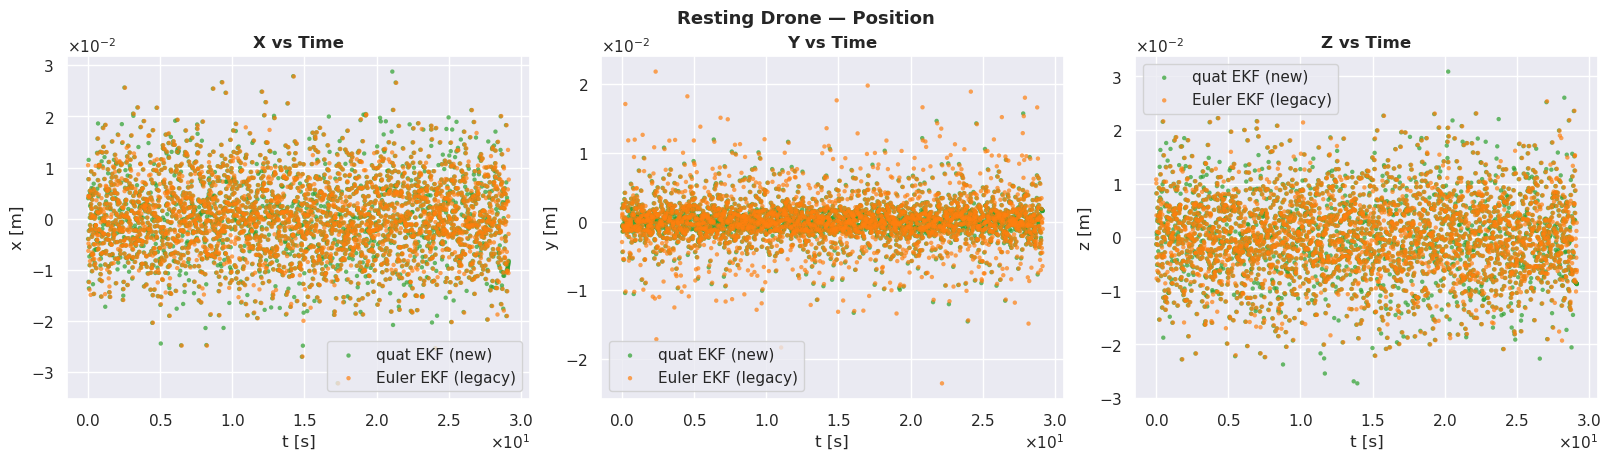

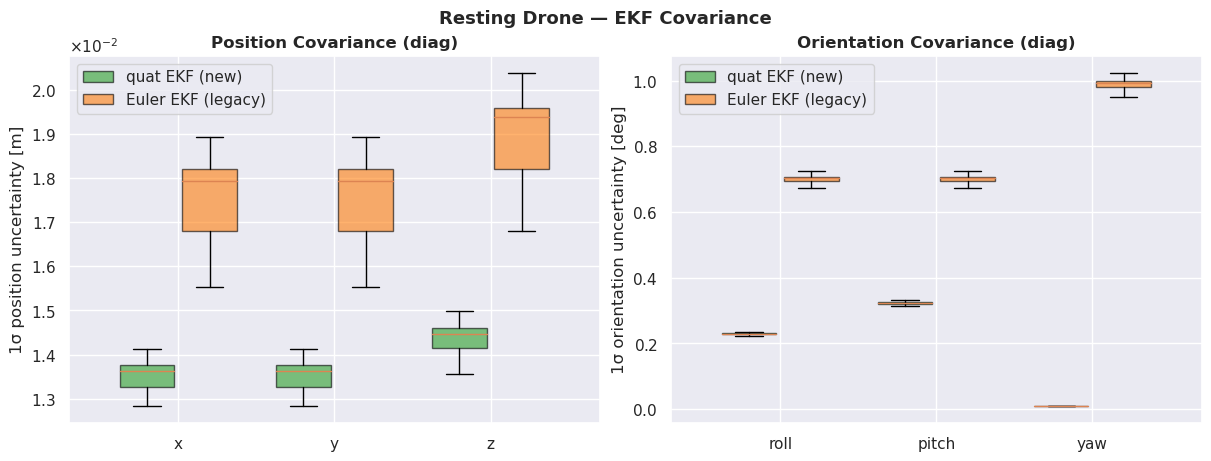

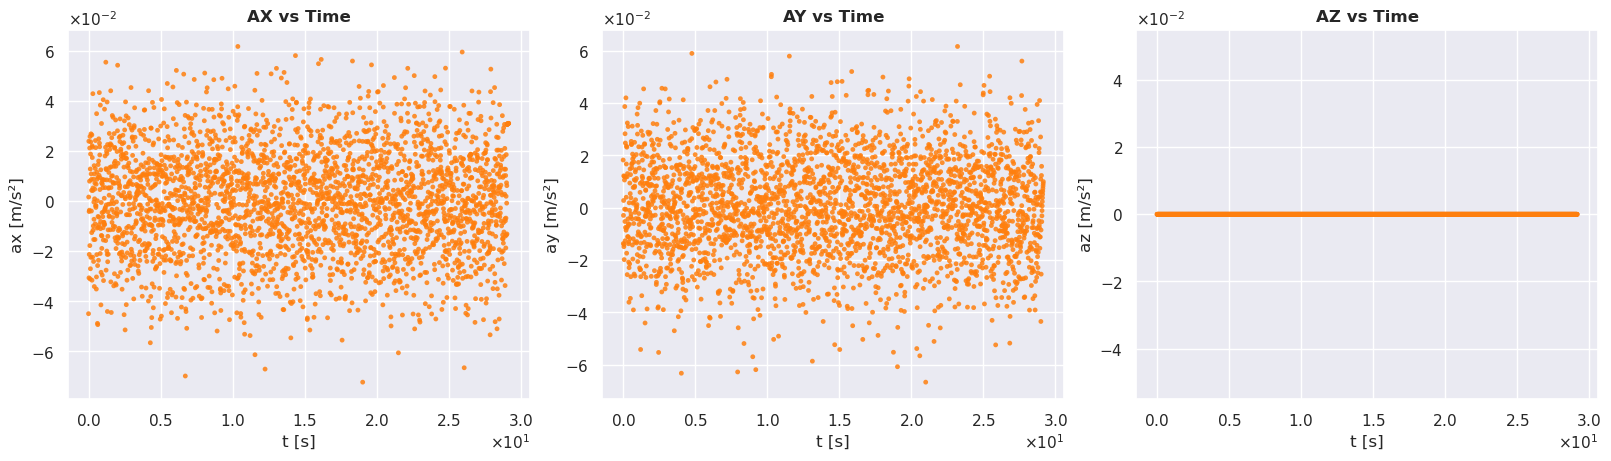

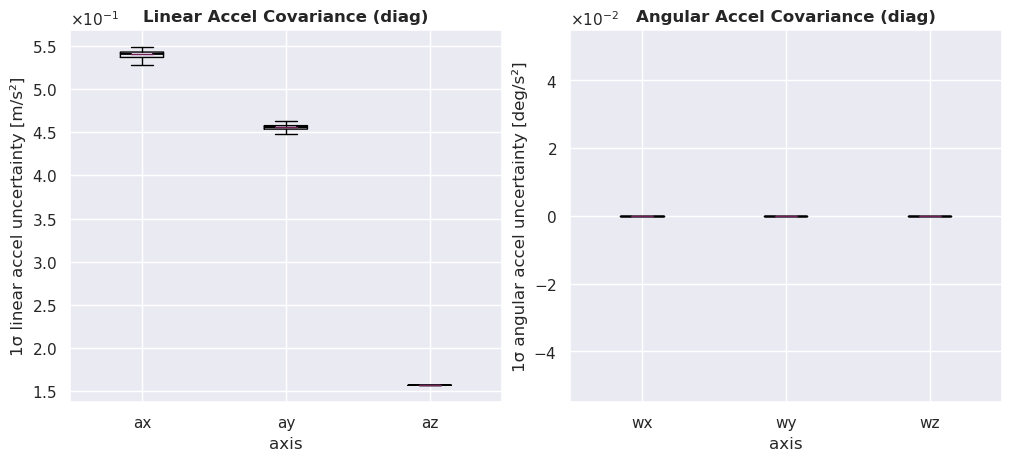

In [117]:
plot_xyz_comparison(rest_ekf, rest_ekf_legacy, title="Resting Drone — Position")
plot_covariance_comparison(rest_ekf, rest_ekf_legacy, title="Resting Drone — EKF Covariance")
plot_time_series_scatter_accel(rest_accel)
plot_accel_covariance_boxplot(rest_accel)

In [118]:
for col, unit in [("x", "m"), ("y", "m"), ("z", "m")]:
    print(f"{col}: mean={rest_ekf[col].mean():.4f} {unit}, std={rest_ekf[col].std():.4f} {unit}")
mean_pos_std = (rest_ekf["x"].std() + rest_ekf["y"].std() + rest_ekf["z"].std()) / 3.0
print(f"Mean position std: {mean_pos_std:.4f} m")

x: mean=0.0001 m, std=0.0079 m
y: mean=0.0000 m, std=0.0025 m
z: mean=0.0000 m, std=0.0078 m
Mean position std: 0.0061 m


---
## Scenario 2 — Constant velocity

Drone moving at constant velocity in x. Ground truth: $v_x = 0.05$ m/s, $v_y = v_z = 0$.

In [119]:
constvel_ekf = pd.read_csv(TESTS_DIR / "const_vel_quat_ekf" / "scenario_data.csv")
constvel_ekf = add_rpy_from_quat(constvel_ekf)
constvel_ekf = subtract_velocity_trend(constvel_ekf, velocity=0.05)
constvel_accel = pd.read_csv(TESTS_DIR / "const_vel_quat_ekf" / "accel_data.csv")

constvel_ekf_legacy = pd.read_csv(LEGACY_TESTS_DIR / "const_vel_defaultqp_controls" / "scenario_data.csv")
constvel_ekf_legacy = add_rpy_from_quat(constvel_ekf_legacy)
constvel_ekf_legacy = trim_to_duration(constvel_ekf_legacy, find_t_rel(constvel_ekf).max())
constvel_ekf_legacy = subtract_velocity_trend(constvel_ekf_legacy, velocity=0.05)

print(f"New    — EKF: {len(constvel_ekf)} samples ({find_t_rel(constvel_ekf).max():.1f} s)")
print(f"Legacy — EKF: {len(constvel_ekf_legacy)} samples ({find_t_rel(constvel_ekf_legacy).max():.1f} s)")

New    — EKF: 2916 samples (29.2 s)
Legacy — EKF: 2916 samples (29.1 s)


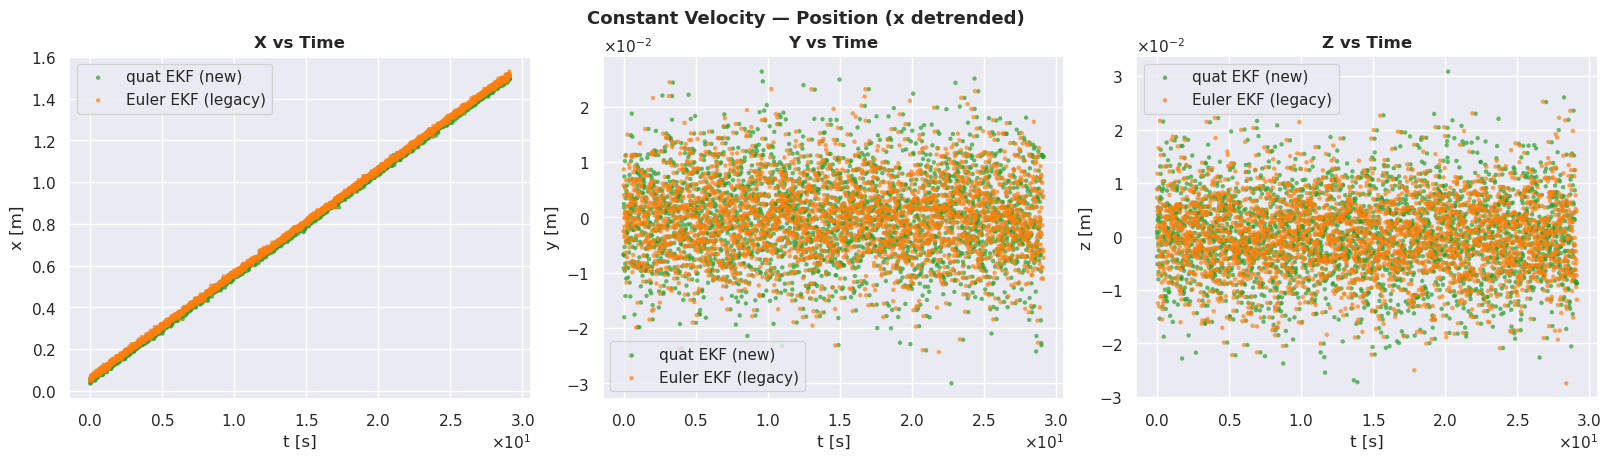

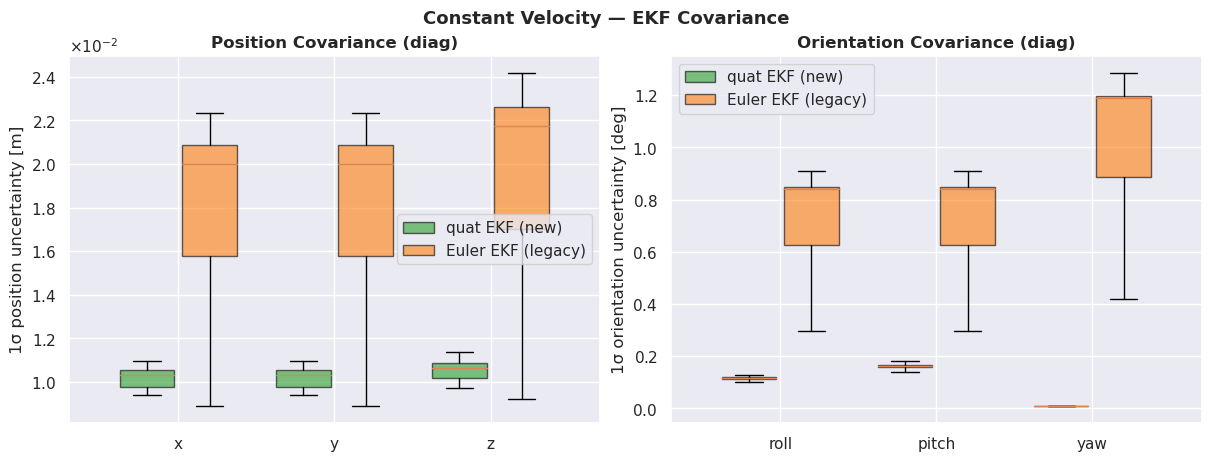

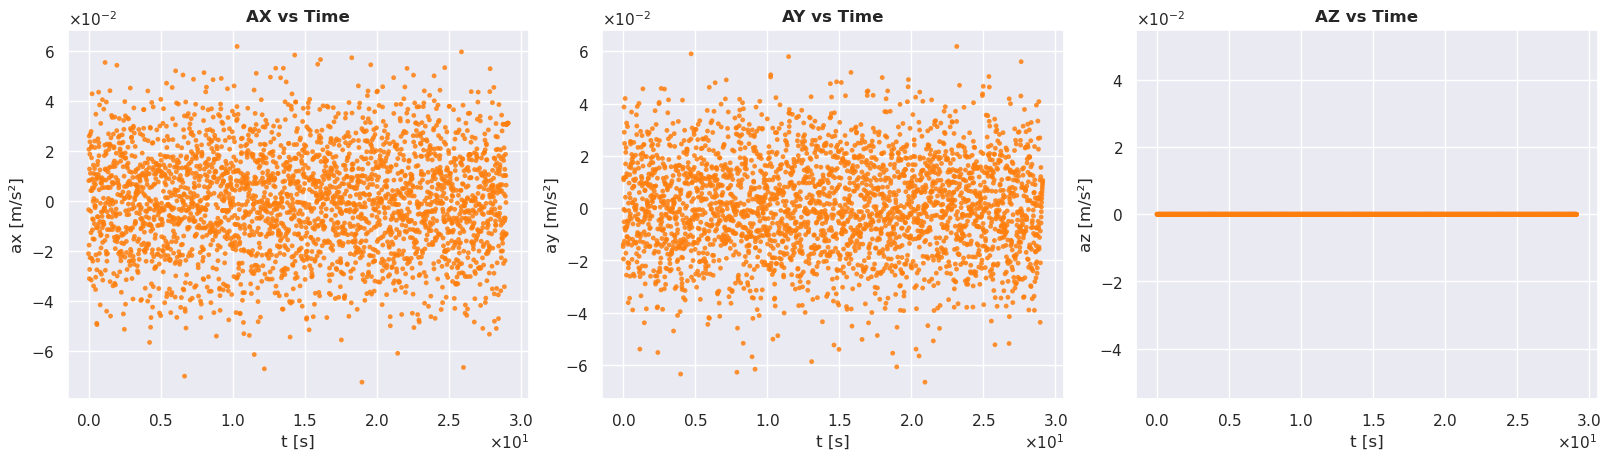

In [120]:
plot_xyz_comparison(constvel_ekf, constvel_ekf_legacy, title="Constant Velocity — Position (x detrended)")
plot_covariance_comparison(constvel_ekf, constvel_ekf_legacy, title="Constant Velocity — EKF Covariance")
plot_time_series_scatter_accel(constvel_accel)

In [121]:
std_x = constvel_ekf["x_detrended"].std()
std_y = constvel_ekf["y"].std()
std_z = constvel_ekf["z"].std()
print(f"x_detrended std: {std_x:.4f} m")
print(f"y std:           {std_y:.4f} m")
print(f"z std:           {std_z:.4f} m")
print(f"Mean position std (detrended): {(std_x + std_y + std_z) / 3.0:.4f} m")

x_detrended std: 0.0079 m
y std:           0.0079 m
z std:           0.0078 m
Mean position std (detrended): 0.0079 m


---
## Scenario 3 — Acceleration

Drone undergoing a commanded acceleration in x.

In [122]:
accel_ekf = pd.read_csv(TESTS_DIR / "accel_quat_ekf" / "scenario_data.csv")
accel_ekf = add_rpy_from_quat(accel_ekf)

accel_accel = pd.read_csv(TESTS_DIR / "accel_quat_ekf" / "accel_data.csv")

print(f"EKF samples: {len(accel_ekf)},  Accel samples: {len(accel_accel)}")

EKF samples: 2918,  Accel samples: 2919


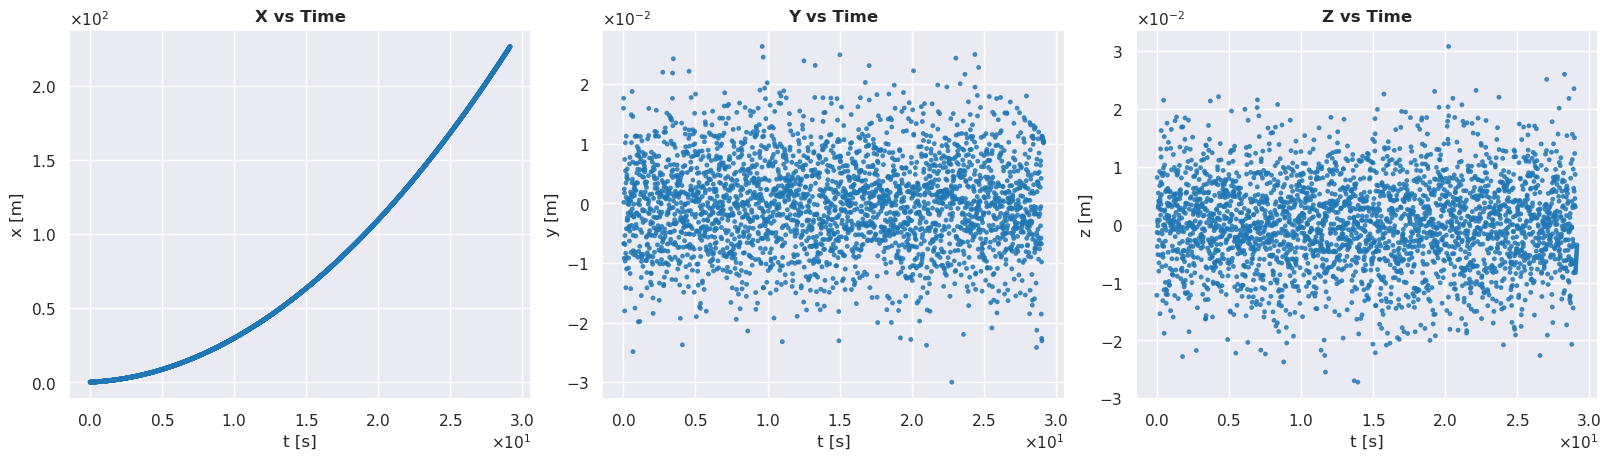

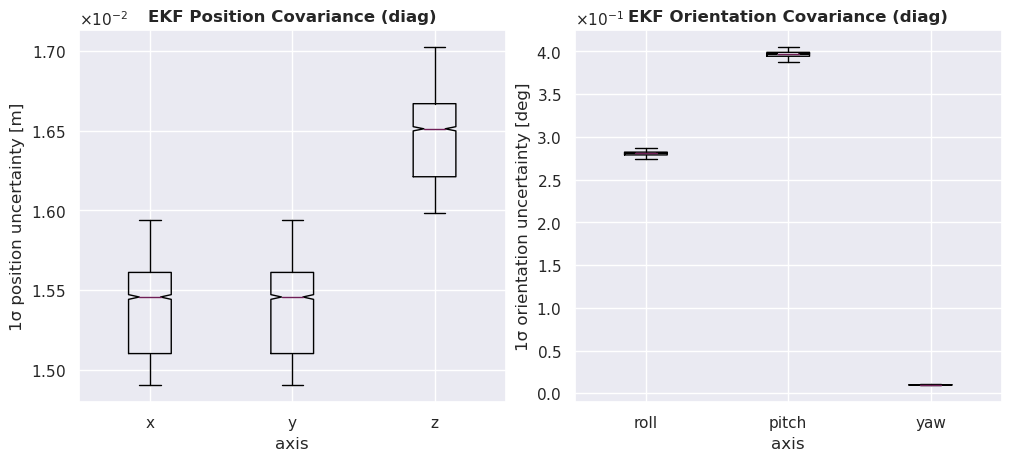

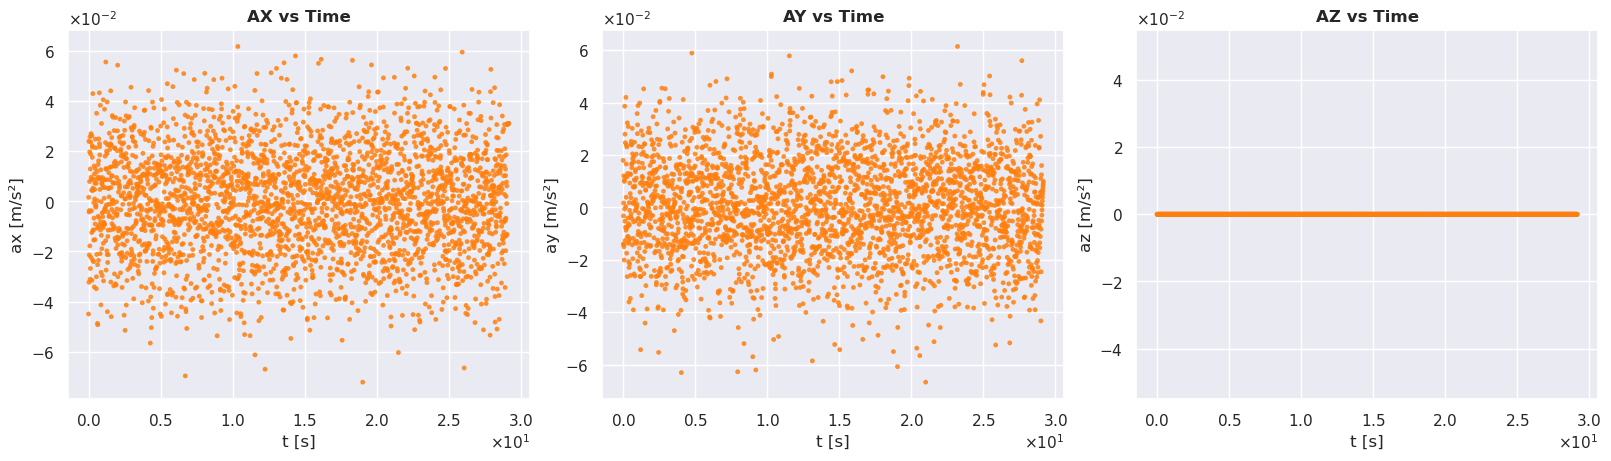

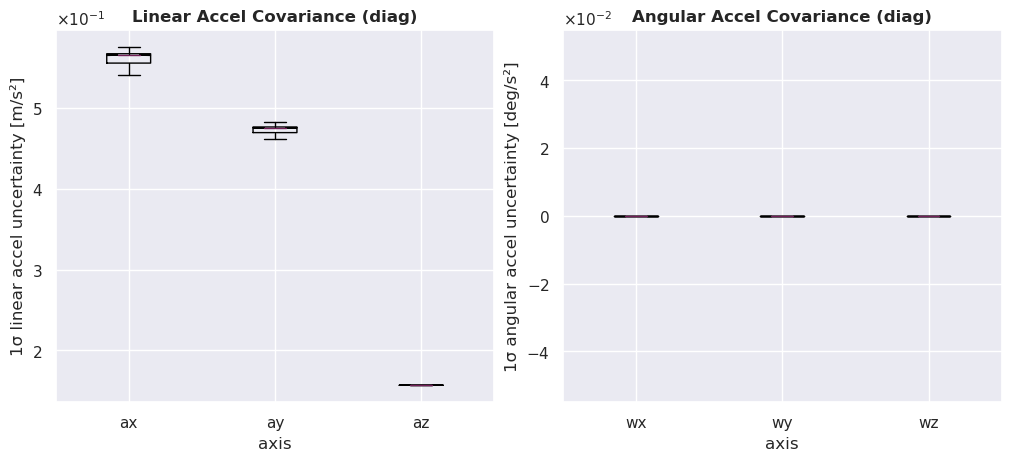

In [123]:
plot_time_series_scatter_xyz(accel_ekf)
plot_state_covariance_boxplot(accel_ekf)
plot_time_series_scatter_accel(accel_accel)
plot_accel_covariance_boxplot(accel_accel)

---
## Scenario 4 — Constant turn

Drone rotating at constant yaw rate. Ground truth: $\dot{\psi} \approx 2.87$ deg/s.

In [124]:
turn_ekf = pd.read_csv(TESTS_DIR / "turn_quat_ekf" / "scenario_data.csv")
turn_ekf = add_rpy_from_quat(turn_ekf)
turn_accel = pd.read_csv(TESTS_DIR / "turn_quat_ekf" / "accel_data.csv")

turn_ekf_legacy = pd.read_csv(LEGACY_TESTS_DIR / "turn_defaultqp_1hz" / "scenario_data.csv")
turn_ekf_legacy = add_rpy_from_quat(turn_ekf_legacy)
turn_ekf_legacy = trim_to_duration(turn_ekf_legacy, find_t_rel(turn_ekf).max())

print(f"New    — EKF: {len(turn_ekf)} samples ({find_t_rel(turn_ekf).max():.1f} s)")
print(f"Legacy — EKF: {len(turn_ekf_legacy)} samples ({find_t_rel(turn_ekf_legacy).max():.1f} s)")

New    — EKF: 2918 samples (29.2 s)
Legacy — EKF: 30 samples (29.0 s)


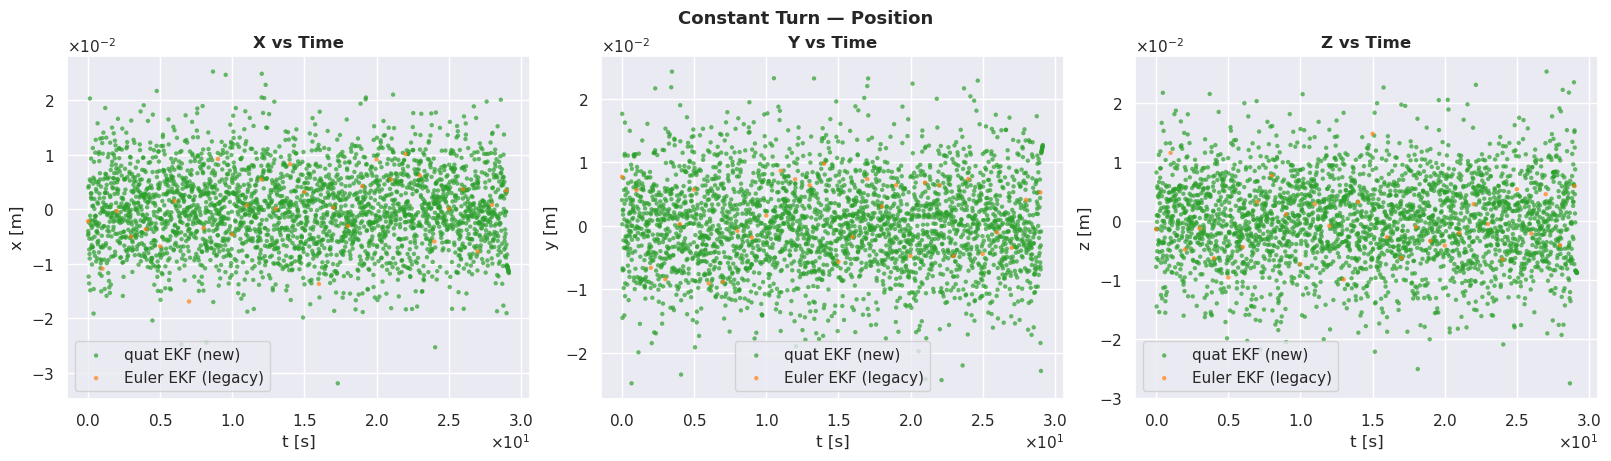

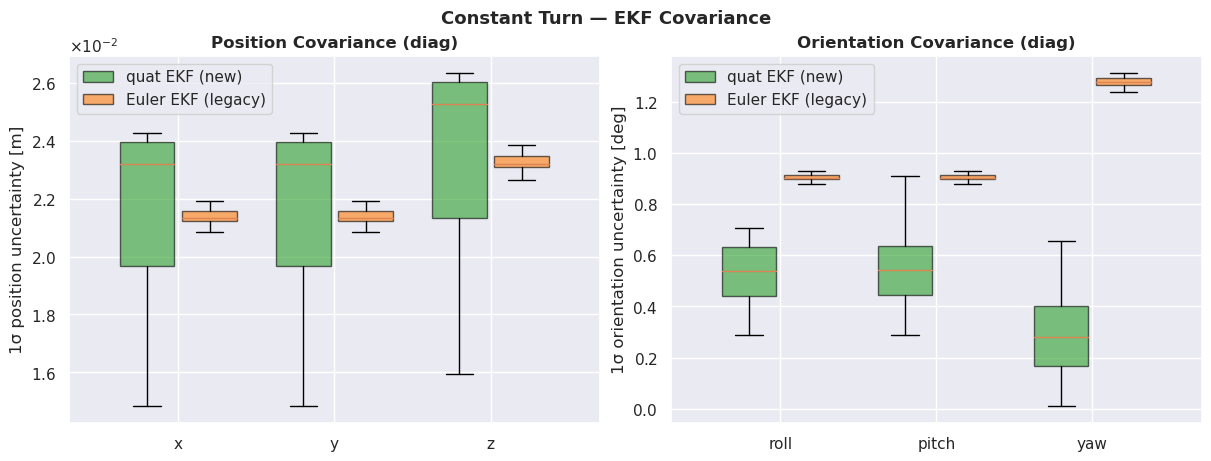

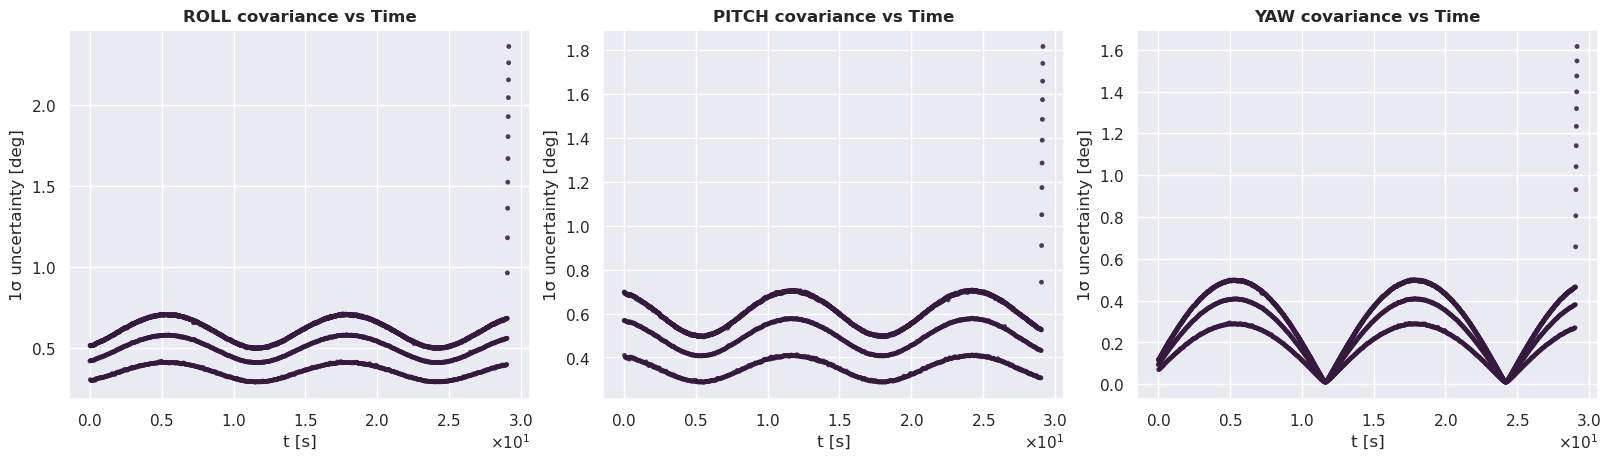

In [125]:
plot_xyz_comparison(turn_ekf, turn_ekf_legacy, title="Constant Turn — Position")
plot_covariance_comparison(turn_ekf, turn_ekf_legacy, title="Constant Turn — EKF Covariance")
plot_time_series_covariance_rpy(turn_ekf)

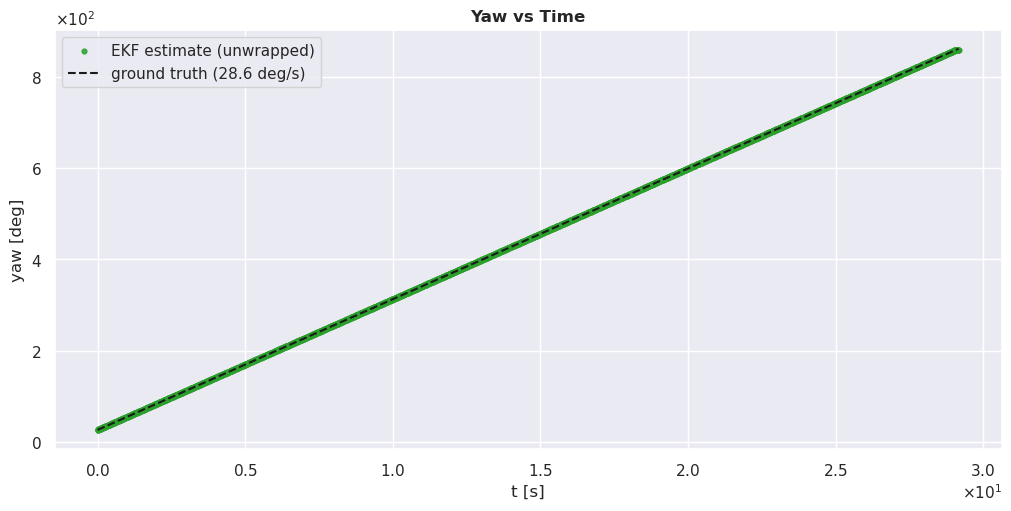

In [126]:
# Yaw vs time — unwrap to remove ±180° discontinuities from atan2
sns.set_theme(style="darkgrid", context="notebook")
t_rel = find_t_rel(turn_ekf)

yaw_rate_deg_s = np.rad2deg(0.5)   # omega = 0.5 rad/s from mock_publisher.cpp
yaw_unwrapped  = np.rad2deg(np.unwrap(np.deg2rad(turn_ekf["yaw_deg"].to_numpy())))
yaw_0          = yaw_unwrapped[0]

fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
ax.scatter(t_rel, yaw_unwrapped, s=12, color="tab:green", label="EKF estimate (unwrapped)", alpha=0.85)
ax.plot(t_rel, yaw_0 + yaw_rate_deg_s * t_rel, "k--", label=f"ground truth ({yaw_rate_deg_s:.1f} deg/s)")
ax.set_xlabel("t [s]")
ax.set_ylabel("yaw [deg]")
ax.set_title("Yaw vs Time", weight="bold")
ax.legend()
plt.show()